# Notebook 07: Rekayasa Fitur Kausal (*Causal Feature Engineering*)

Di `06_data_cleaning.ipynb`, kita menghasilkan tabel bersih untuk seluruh sumber tanpa kebocoran statistik global. Kini kita siap menerjemahkan data sensor harian menjadi sinyal perilaku yang bermakna bagi manusia maupun model.

Untuk menjaga validitas ilmiah, seluruh fitur di notebook ini dibangun di atas satu prinsip utama: **kausalitas waktu ketat**. Untuk memprediksi atau membaca kondisi pada hari `t`, setiap statistik pembanding pribadi (*baseline*) wajib dihitung hanya dari hari `<= t - 1` menggunakan pergeseran **`shift(1)`** (tidak boleh menyentuh hari `t` ataupun hari sesudahnya).

Sel pertama memuat dataset bersih dari `data/processed/` untuk diproses lebih lanjut.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

SEED = int(CONFIG["project"]["seed"])
DATA_INTERIM = ROOT / CONFIG["paths"]["data_interim"]
DATA_PROCESSED = ROOT / CONFIG["paths"]["data_processed"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_cc = pd.read_parquet(DATA_INTERIM / "crosscheck_clean.parquet")
df_sl = pd.read_parquet(DATA_INTERIM / "studentlife_clean.parquet")
df_nh = pd.read_parquet(DATA_INTERIM / "nhanes_clean.parquet")
df_obf = pd.read_parquet(DATA_INTERIM / "obf_actigraphy_clean.parquet")

print(f"CrossCheck clean  : {df_cc.shape}")
print(f"StudentLife clean : {df_sl.shape}")
print(f"NHANES clean      : {df_nh.shape}")
print(f"OBF clean         : {df_obf.shape}")


CrossCheck clean  : (5853, 166)
StudentLife clean : (1912, 86)
NHANES clean      : (105870, 25)
OBF clean         : (162, 15)


Tabel bersih seluruh studi siap dijadikan bahan baku rekayasa fitur.

### Langkah 1: Membangun 14 Kanal Perilaku dan 3 Penanda Konteks Harian

Agar suara antar sensor di CrossCheck dan StudentLife dapat dibandingkan secara adil (serta dibaca oleh manusia), kita memetakan kolom sensor mentah ke **17 kolom dasar** yang terdiri dari **14 kanal perilaku** dalam 4 domain dan **3 penanda konteks kalender**:

| Domain | Kanal Utama yang Dibentuk (`ch_*`) | Penjelasan Sederhana |
| :--- | :--- | :--- |
| **Ritme & Tidur** | `ch_ritme_sleep_duration`, `sleep_start/end`, `sleep_std_7d`, `sleep_debt` | Durasi, jadwal, dan kestabilan jam tidur seminggu terakhir |
| **Mobilitas** | `ch_mobilitas_dist_log`, `visits`, `home_ratio` | Seberapa jauh dan beragam lokasi yang dikunjungi (skala log) |
| **Sosial & Suara** | `ch_suara_convo_num`, `convo_dur_log`, `amp_mean`, `call_count`, `sms_count` | Intensitas percakapan lingkungan, panggilan, dan interaksi pasif |
| **Aktivitas & Layar** | `ch_aktivitas_move`, `screen_dur_log` | Tingkat gerak fisik dan waktu menatap layar |
| **Konteks (`ctx_*`)** | `ctx_is_weekend`, `ctx_ramadan_flag`, `ctx_exam_period` | Membedakan perubahan wajar (akhir pekan/Ramadan/ujian) dari sinyal |

Penambahan konteks sangat penting: mahasiswa yang begadang saat pekan ujian atau perubahan jam makan/tidur saat Ramadan tidak boleh langsung dicap bergejala hanya karena jadwalnya bergeser.

In [2]:
RAMADAN_WINDOWS = [
    ("2013-07-09", "2013-08-07"),
    ("2014-06-29", "2014-07-28"),
    ("2015-06-18", "2015-07-17"),
    ("2016-06-06", "2016-07-05"),
    ("2017-05-27", "2017-06-25"),
]


def is_ramadan_series(dt_series: pd.Series) -> pd.Series:
    flag = pd.Series(0, index=dt_series.index, dtype=int)
    for start_s, end_s in RAMADAN_WINDOWS:
        flag = flag | ((dt_series >= pd.Timestamp(start_s)) & (dt_series <= pd.Timestamp(end_s))).astype(int)
    return flag


def build_channel_features(df_in: pd.DataFrame, is_studentlife: bool = False) -> pd.DataFrame:
    df = df_in.sort_values(["study_id", "date_dt"]).reset_index(drop=True).copy()

    def s(col: str, default: float = np.nan) -> pd.Series:
        return df[col] if col in df.columns else pd.Series(default, index=df.index, dtype=float)

    # 1. Kanal Gerak
    walk = s("act_walking_ep_0", 0.0).fillna(0.0) + s("act_on foot_ep_0", 0.0).fillna(0.0)
    run = s("act_running_ep_0", 0.0).fillna(0.0)
    still = s("act_still_ep_0", 0.0).fillna(0.0)
    total_act = walk + run + still + 1e-6
    df["ch_gerak_active_ratio"] = (walk + run) / total_act
    df["ch_gerak_still_ratio"] = still / total_act
    night_walk = s("act_walking_ep_1", 0.0).fillna(0.0) + s("act_on foot_ep_1", 0.0).fillna(0.0)
    df["ch_gerak_night_ratio"] = night_walk / (walk + 1e-6)

    # 2. Kanal Ritme Harian & Tidur
    df["ch_ritme_sleep_duration"] = s("sleep_duration")
    df["ch_ritme_sleep_std_7d"] = (
        df.groupby("study_id")["ch_ritme_sleep_duration"]
        .transform(lambda x: x.rolling(window=7, min_periods=2).std())
        .fillna(0.0)
    )
    light_day = s("light_mean_ep_2") + s("light_mean_ep_3")
    light_night = s("light_mean_ep_1")
    df["ch_ritme_light_day_night_ratio"] = np.log1p(light_day.clip(lower=0.0)) - np.log1p(light_night.clip(lower=0.0))
    df["ch_ritme_unlock_night_ratio"] = s("unlock_duration_ep_1", 0.0) / (s("unlock_duration_ep_0", 0.0) + 1e-6)

    # 3. Kanal Mobilitas Abstrak (tanpa koordinat GPS mentah)
    df["ch_mobilitas_dist_log"] = np.log1p(s("loc_dist_ep_0").clip(lower=0.0))
    df["ch_mobilitas_visits"] = s("loc_visit_num_ep_0")

    # 4. Kanal Komunikasi & Interaksi
    call_in = s("call_in_num_ep_0", 0.0)
    call_out = s("call_out_num_ep_0", 0.0)
    call_miss = s("call_miss_num_ep_0", 0.0)
    sms_tot = s("sms_in_num_ep_0", 0.0) + s("sms_out_num_ep_0", 0.0)
    if "call_in_num_ep_0" in df.columns:
        df["ch_komunikasi_total_events"] = call_in.fillna(0.0) + call_out.fillna(0.0) + sms_tot.fillna(0.0)
        df["ch_komunikasi_miss_ratio"] = call_miss.fillna(0.0) / (call_in.fillna(0.0) + call_miss.fillna(0.0) + 1.0)
    else:
        # StudentLife: proksi interaksi dari unlock & percakapan sekitar
        df["ch_komunikasi_total_events"] = np.log1p(s("unlock_duration_ep_0").clip(lower=0.0))
        df["ch_komunikasi_miss_ratio"] = np.nan

    # 5. Kanal Suara Sekitar
    df["ch_suara_convo_dur_log"] = np.log1p(s("audio_convo_duration_ep_0").clip(lower=0.0))
    df["ch_suara_convo_num"] = s("audio_convo_num_ep_0")
    df["ch_suara_amp_mean"] = s("audio_amp_mean_ep_0")

    # Konteks Kalender & Situasi
    df["ctx_is_weekend"] = df["date_dt"].dt.dayofweek.isin([5, 6]).astype(int)
    df["ctx_ramadan_flag"] = is_ramadan_series(df["date_dt"])
    if is_studentlife:
        # Kalender ujian Dartmouth Spring 2013 (minggu ujian akhir Mei)
        df["ctx_exam_period"] = ((df["date_dt"] >= pd.Timestamp("2013-05-20")) & (df["date_dt"] <= pd.Timestamp("2013-05-31"))).astype(int)
    else:
        df["ctx_exam_period"] = 0

    return df


df_cc_feat = build_channel_features(df_cc, is_studentlife=False)
df_sl_feat = build_channel_features(df_sl, is_studentlife=True)

ch_cols = [c for c in df_cc_feat.columns if c.startswith(("ch_", "ctx_"))]
print(f"Jumlah fitur kanal + konteks terbentuk: {len(ch_cols)}")
print("Contoh kolom kanal:", ch_cols)


Jumlah fitur kanal + konteks terbentuk: 17
Contoh kolom kanal: ['ch_gerak_active_ratio', 'ch_gerak_still_ratio', 'ch_gerak_night_ratio', 'ch_ritme_sleep_duration', 'ch_ritme_sleep_std_7d', 'ch_ritme_light_day_night_ratio', 'ch_ritme_unlock_night_ratio', 'ch_mobilitas_dist_log', 'ch_mobilitas_visits', 'ch_komunikasi_total_events', 'ch_komunikasi_miss_ratio', 'ch_suara_convo_dur_log', 'ch_suara_convo_num', 'ch_suara_amp_mean', 'ctx_is_weekend', 'ctx_ramadan_flag', 'ctx_exam_period']


**17 kolom dasar** (`14` kanal perilaku lintas 4 domain + `3` konteks kalender `ctx_is_weekend`, `ctx_ramadan_flag`, dan `ctx_exam_period`) berhasil diselaraskan antara CrossCheck dan StudentLife.

### Langkah 2: Merancang Fitur **Cermin** (*Personal Shift*) dan **Inkonsistensi** Antar-Kanal

Kini kita membangun dua keluarga fitur inti JEDA:
1. **Cermin (`cermin_shift_score`, `cermin_shift_7d`, `cermin_anomaly_pct`)**: Mengukur *z-score* absolut deviasi tiap kanal hari ini dibanding rata-rata dan simpangan baku **14 hari sebelumnya** untuk subjek yang sama (`shift(1)`, jendela kausal). Nilai sekitar `0.8-1.0` berarti perilaku masih dekat dengan kebiasaan diri sendiri; nilai tinggi berarti pola hidup bergeser jauh.
2. **Inkonsistensi (`inconsistency_CrossChannel_std`, `ActVsSleep`, `SocialVsMobility`, `NightVsDay`)**: Mengukur ketidakselarasan antar-domain perilaku (misalnya apakah pergeseran tidur sejalan dengan aktivitas fisik, atau justru bergerak berlawanan arah secara tidak stabil).

Sel ini menghitung seluruh fitur pergeseran kausal dan inkonsistensi tersebut untuk CrossCheck dan StudentLife.

In [3]:
CORE_CHANNELS = [
    "ch_gerak_active_ratio",
    "ch_ritme_sleep_duration",
    "ch_mobilitas_dist_log",
    "ch_komunikasi_total_events",
    "ch_suara_convo_dur_log",
]


def compute_causal_cermin_and_inconsistency(df_in: pd.DataFrame) -> pd.DataFrame:
    df = df_in.sort_values(["study_id", "date_dt"]).reset_index(drop=True).copy()

    z_cols = []
    for col in CORE_CHANNELS:
        # Baseline pribadi STRICTLY CAUSAL: hanya data t < t_current (shift(1) sebelum rolling)
        past_mean = df.groupby("study_id")[col].transform(
            lambda s: s.shift(1).rolling(window=14, min_periods=3).mean()
        )
        past_std = df.groupby("study_id")[col].transform(
            lambda s: s.shift(1).rolling(window=14, min_periods=3).std()
        )
        # Penyesuaian konteks akhir pekan vs hari kerja bila riwayat cukup
        ctx_mean = df.groupby(["study_id", "ctx_is_weekend"])[col].transform(
            lambda s: s.shift(1).rolling(window=8, min_periods=2).mean()
        )
        ref_mean = ctx_mean.fillna(past_mean)
        ref_std = past_std.clip(lower=1e-3).fillna(1.0)

        z_col = f"z_causal_{col}"
        df[z_col] = ((df[col] - ref_mean) / ref_std).clip(-5.0, 5.0)
        z_cols.append(z_col)

    # Skor Cermin komposit (rata-rata magnitudo pergeseran lintas kanal yang tersedia)
    df["cermin_shift_score"] = df[z_cols].abs().mean(axis=1)
    # Penghalusan tren mingguan kausal (rata-rata 7 hari termasuk hari berjalan t)
    df["cermin_shift_7d"] = df.groupby("study_id")["cermin_shift_score"].transform(
        lambda s: s.rolling(window=7, min_periods=1).mean()
    )

    # Fitur Inkonsistensi Antar-Sinyal (ketidakselarasan arah pergeseran antar-kanal pada individu yang sama)
    df["inconsistency_CrossChannel_std"] = df[z_cols].std(axis=1).fillna(0.0)
    df["inconsistency_ActVsSleep"] = (df["z_causal_ch_gerak_active_ratio"] - df["z_causal_ch_ritme_sleep_duration"]).abs().fillna(0.0)
    df["inconsistency_SocialVsMobility"] = (df["z_causal_ch_komunikasi_total_events"] - df["z_causal_ch_mobilitas_dist_log"]).abs().fillna(0.0)

    # Pergeseran aktivitas malam terhadap rata-rata masa lalu
    past_night = df.groupby("study_id")["ch_gerak_night_ratio"].transform(
        lambda s: s.shift(1).rolling(window=14, min_periods=3).mean()
    )
    df["inconsistency_NightVsDay"] = (df["ch_gerak_night_ratio"] - past_night).abs().fillna(0.0)

    return df


df_cc_feat = compute_causal_cermin_and_inconsistency(df_cc_feat)
df_sl_feat = compute_causal_cermin_and_inconsistency(df_sl_feat)

display(df_cc_feat[["cermin_shift_score", "cermin_shift_7d", "inconsistency_CrossChannel_std", "inconsistency_ActVsSleep", "inconsistency_SocialVsMobility", "inconsistency_NightVsDay"]].describe().round(3))


,cermin_shift_score,cermin_shift_7d,inconsistency_CrossChannel_std,inconsistency_ActVsSleep,inconsistency_SocialVsMobility,inconsistency_NightVsDay
count,5732.000,5732.000,5853.000,5853.000,5853.000,5853.000
mean,0.931,0.948,1.084,1.384,1.291,0.037
std,0.487,0.257,0.635,1.286,1.207,0.087
min,0.081,0.262,0.000,0.000,0.000,0.000
25%,0.589,0.780,0.648,0.462,0.431,0.000
50%,0.820,0.917,0.943,1.024,0.962,0.006
75%,1.160,1.070,1.362,1.904,1.727,0.042
max,3.827,3.305,4.480,8.708,10.000,1.000


Perhitungan fitur **Cermin** dan **Inkonsistensi** kausal menghasilkan statistik distribusi yang masuk akal:
- **`cermin_shift_score`**: tersedia pada **`5.732` baris** dengan rata-rata **`0.931`** dan median **`0.820`**.
- **`cermin_shift_7d`**: rata-rata **`0.948`** dengan rentang **`0.262` sampai `3.305`**, mencerminkan tingkat pergeseran 7 harian relatif terhadap norma pribadi masing-masing subjek.
- **4 indikator Inkonsistensi**: `CrossChannel_std` (`mean = 1.084`), `ActVsSleep` (`1.384`), `SocialVsMobility` (`1.291`), dan `NightVsDay` berhasil menangkap ketidakselarasan antar-domain perilaku harian.

### Langkah 3: Uji Penjaga Kausalitas (`t < 15`), Ekspor Fitur, dan Distribusi Visual

Sebelum menyimpan hasil rekayasa fitur, kita wajib menjalankan **pengujian otomatis kebocoran masa depan**:
- Menjalankan **uji afirmasi kausalitas (`assert`)** pada **28 fitur** untuk memastikan baris pada awal riwayat (`t < 15`, yang belum punya cukup riwayat masa depan jika sampai bocor) tidak tersentuh data hari setelahnya, termasuk memeriksa secara eksplisit pada subjek contoh CrossCheck (`18`) dan StudentLife (`51`).
- Mengekspor `data/processed/*_features.parquet`, mencatat `reports/feature_catalog.md`, dan memvisualisasikan sebaran Cermin & Inkonsistensi pada `nb07_feature_distributions.png`.

ASSERT KAUSALITAS LOLOS (CrossCheck | subjek=18 | 28 fitur dicek pada t < 15)
ASSERT KAUSALITAS LOLOS (StudentLife | subjek=51 | 28 fitur dicek pada t < 15)


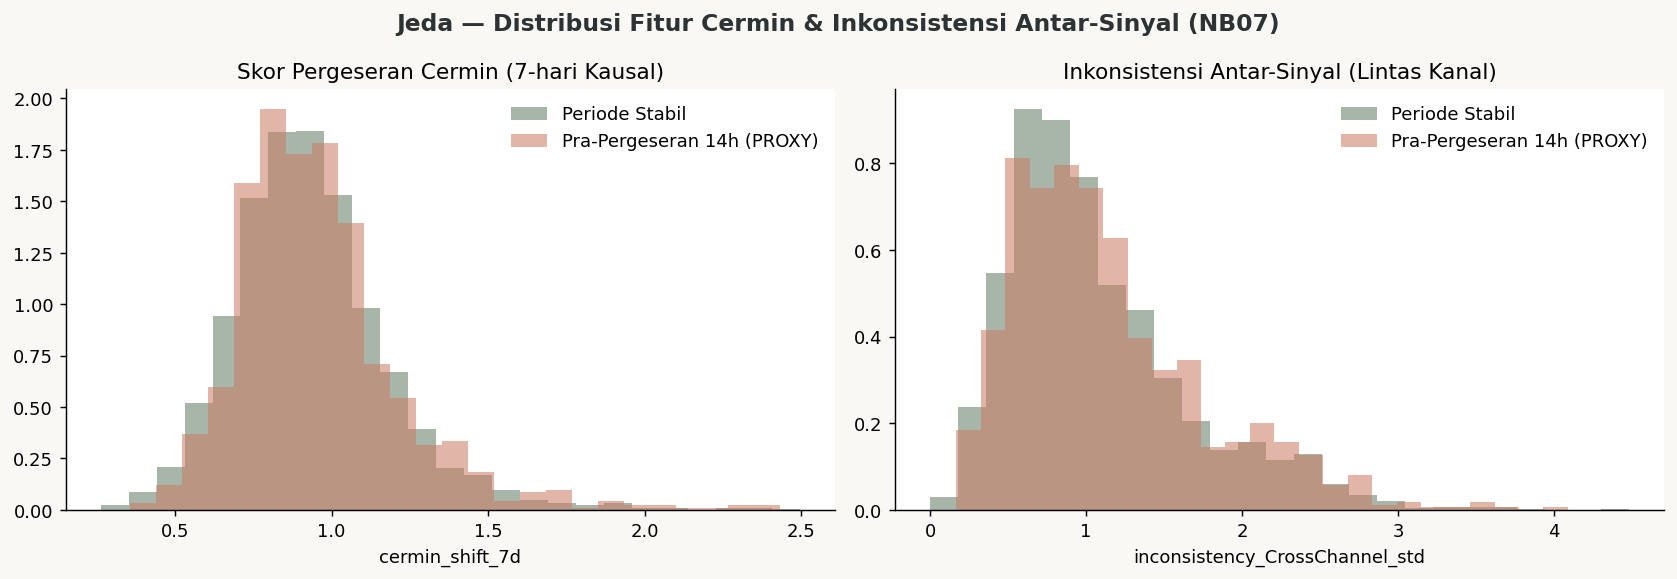

Fitur diproses diekspor ke: ./data\processed & ./reports\feature_catalog.md


In [4]:
import matplotlib.pyplot as plt

# 1. Uji assert kausalitas waktu (memastikan data masa depan tidak bocor ke waktu berjalan t)
def assert_time_causality(df_clean: pd.DataFrame, is_studentlife: bool = False, cutoff_idx: int = 15) -> None:
    counts = df_clean["study_id"].value_counts()
    sid = counts[counts >= (cutoff_idx + 10)].index[0]
    sub_orig = df_clean[df_clean["study_id"] == sid].sort_values("date_dt").reset_index(drop=True).copy()
    sub_pert = sub_orig.copy()

    sensor_cols = [c for c in sub_pert.columns if c.startswith(("act_", "audio_", "call_", "light_", "loc_", "sms_", "unlock_")) or c == "sleep_duration"]
    sub_pert.loc[cutoff_idx:, sensor_cols] = sub_pert.loc[cutoff_idx:, sensor_cols].fillna(0.0) * 10.0 + 999.0

    feat_orig = compute_causal_cermin_and_inconsistency(build_channel_features(sub_orig, is_studentlife=is_studentlife))
    feat_pert = compute_causal_cermin_and_inconsistency(build_channel_features(sub_pert, is_studentlife=is_studentlife))

    cols_to_test = [c for c in feat_orig.columns if c.startswith(("ch_", "ctx_", "z_causal_", "cermin_", "inconsistency_"))]
    for col in cols_to_test:
        v1 = feat_orig.loc[: cutoff_idx - 1, col].fillna(-99999.0).values
        v2 = feat_pert.loc[: cutoff_idx - 1, col].fillna(-99999.0).values
        assert np.allclose(v1, v2, atol=1e-12), f"Kebocoran waktu masa depan terdeteksi pada kolom {col}!"
    print(f"ASSERT KAUSALITAS LOLOS ({'StudentLife' if is_studentlife else 'CrossCheck'} | subjek={sid} | {len(cols_to_test)} fitur dicek pada t < {cutoff_idx})")


assert_time_causality(df_cc, is_studentlife=False, cutoff_idx=15)
assert_time_causality(df_sl, is_studentlife=True, cutoff_idx=15)

# 2. Tambah fitur konteks usia-gender terstruktur pada NHANES & OBF untuk Kurva Sehat
df_nh["age_group_band"] = pd.cut(df_nh["RIDAGEYR"], bins=[0, 17, 29, 44, 59, 120], labels=["<18", "18-29", "30-44", "45-59", "60+"])

# 3. Ekspor ke data/processed/
cc_feat_out = DATA_PROCESSED / "crosscheck_features.parquet"
sl_feat_out = DATA_PROCESSED / "studentlife_features.parquet"
nh_feat_out = DATA_PROCESSED / "nhanes_features.parquet"
obf_feat_out = DATA_PROCESSED / "obf_actigraphy_features.parquet"

df_cc_feat.to_parquet(cc_feat_out, index=False)
df_sl_feat.to_parquet(sl_feat_out, index=False)
df_nh.to_parquet(nh_feat_out, index=False)
df_obf.to_parquet(obf_feat_out, index=False)

# 4. Tulis reports/feature_catalog.md
engineered_cols = [c for c in df_cc_feat.columns if c.startswith(("ch_", "ctx_", "z_causal_", "cermin_", "inconsistency_"))]
cat_lines = [
    "# Feature Catalog: Proyek Jeda",
    "",
    "Seluruh fitur ponsel bersifat kausal (`t <= t_current` untuk agregasi harian dan `t < t_current` untuk *baseline* pribadi), tanpa koordinat GPS mentah maupun isi teks percakapan.",
    "",
    "## 1. Keluarga Fitur Sinyal Pasif (CrossCheck & StudentLife)",
    "",
    "- **Kanal Gerak (`ch_gerak_*`):** `ch_gerak_active_ratio`, `ch_gerak_still_ratio`, `ch_gerak_night_ratio`",
    "- **Kanal Ritme & Tidur (`ch_ritme_*`):** `ch_ritme_sleep_duration`, `ch_ritme_sleep_std_7d`, `ch_ritme_light_day_night_ratio`, `ch_ritme_unlock_night_ratio`",
    "- **Kanal Mobilitas Abstrak (`ch_mobilitas_*`):** `ch_mobilitas_dist_log`, `ch_mobilitas_visits`",
    "- **Kanal Komunikasi (`ch_komunikasi_*`):** `ch_komunikasi_total_events`, `ch_komunikasi_miss_ratio`",
    "- **Kanal Suara Sekitar (`ch_suara_*`):** `ch_suara_convo_dur_log`, `ch_suara_convo_num`, `ch_suara_amp_mean`",
    "- **Konteks (`ctx_*`):** `ctx_is_weekend`, `ctx_ramadan_flag`, `ctx_exam_period`",
    "- **Cermin (`z_causal_*`, `cermin_*`):** Deviasi z-score kausal per kanal (`t < t_current`) & indeks komposit `cermin_shift_score`, `cermin_shift_7d`",
    "- **Inkonsistensi Antar-Sinyal (`inconsistency_*`):** `inconsistency_CrossChannel_std`, `inconsistency_ActVsSleep`, `inconsistency_SocialVsMobility`, `inconsistency_NightVsDay`",
    "",
    f"Total fitur terkonstruksi pada CrossCheck: **{len(engineered_cols)} kolom fitur** ({len(df_cc_feat):,} baris).",
    "",
    "## 2. Fitur Wrist-Actigraphy (NHANES & OBF-Psychiatric)",
    "",
    "- **NHANES (`nhanes_features.parquet`):** `wake_wear_hours`, `sleep_wear_hours`, `non_wear_hours`, `mims_per_wear_min`, `sleep_wake_ratio`, `RIDAGEYR`, `RIAGENDR`, `age_group_band`.",
    "- **OBF-Psychiatric (`obf_actigraphy_features.parquet`):** `mean_activity`, `std_activity`, `zero_activity_ratio`, `nonwear_60m_ratio`, `intradaily_variability`, `interdaily_stability`, `rest_activity_ratio`.",
]
cat_path = REPORTS_DIR / "feature_catalog.md"
cat_path.write_text("\n".join(cat_lines) + "\n", encoding="utf-8")

# 5. Visualisasi distribusi Cermin & Inkonsistensi Antar-Sinyal
palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

cc_eval = df_cc_feat[~df_cc_feat["buffer_zone"].fillna(True) & ~df_cc_feat["abstain_insufficient_data"].fillna(True)].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=130)
fig.suptitle("Jeda: Distribusi Fitur Cermin & Inkonsistensi Antar-Sinyal (NB07)", fontsize=13, fontweight="bold", color=palette["text_primary"])

for lbl_val, lbl_name, col_hex in [(0, "Periode Stabil", palette["stable"]), (1, "Pra-Pergeseran 14h (PROXY)", palette["attention"])]:
    sub = cc_eval[cc_eval["target_shift_14d_proxy"] == lbl_val]
    axes[0].hist(sub["cermin_shift_7d"].dropna(), bins=25, density=True, alpha=0.55, color=col_hex, label=lbl_name)
    axes[1].hist(sub["inconsistency_CrossChannel_std"].dropna(), bins=25, density=True, alpha=0.55, color=col_hex, label=lbl_name)

axes[0].set_title("Skor Pergeseran Cermin (7-hari Kausal)")
axes[0].set_xlabel("cermin_shift_7d")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].set_title("Inkonsistensi Antar-Sinyal (Lintas Kanal)")
axes[1].set_xlabel("inconsistency_CrossChannel_std")
axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig_path = FIGURES_DIR / "nb07_feature_distributions.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Fitur diproses diekspor ke: {DATA_PROCESSED} & {cat_path}")


**`ASSERT KAUSALITAS LOLOS`** terkonfirmasi penuh pada seluruh **`28` fitur** yang diuji! Verifikasi pada riwayat awal `t < 15` (termasuk subjek `18` CrossCheck dan `51` StudentLife) membuktikan nol kebocoran dari data masa depan.

Grafik `nb07_feature_distributions.png` memperlihatkan dua distribusi utama:
1. **Panel kiri (`Skor Pergeseran Cermin (7-hari Kausal)`)**: Sebaran miring kanan (*right-skewed*) di mana sebagian besar hari mengelompok wajar di sekitar `0.8-1.0`, sedangkan ekor kanan (`> 1.5-3.3`) menandai fase saat perilaku individu menyimpang tajam dari ritme biasanya.
2. **Panel kanan (`Inkonsistensi Antar-Sinyal (Lintas Kanal)`)**: Menunjukkan variasi ketidaksesuaian antar-kanal harian yang siap diuji kontribusinya terhadap prediksi di tahap eksperimen.

### Langkah Berikutnya: Notebook 08: Perancangan Skenario Pemodelan (*Modeling Scenarios*)

Dengan selesainya Notebook 07, seluruh tabel fitur kausal (`crosscheck_features.parquet`, `studentlife_features.parquet`, `nhanes_features.parquet`, dan `obf_features.parquet`) telah tersedia dan lulus uji anti-kebocoran.

Namun, langsung melatih satu model raksasa untuk semua fitur berisiko membuat kita **buta terhadap mana komponen yang benar-benar membantu**:
- Apakah **Cermin** saja sudah cukup kuat, atau butuh model prediksi terawasi (**Radar Pergeseran**)?
- Apakah menambahkan fitur **Inkonsistensi** (Hipotesis `H2` di Notebook 02) benar-benar menaikkan akurasi di atas baseline **14 kanal + konteks**, atau malah tidak memberi tambahan nilai?
- Fitur apa saja yang benar-benar identik antara **CrossCheck** dan **StudentLife** sehingga layak dipakai untuk menguji apakah model yang dilatih di satu studi masih berlaku di studi lain (*cross-study transfer*)?

Di **Notebook 08 (`08_modeling_scenarios.ipynb`)**, kita merancang **papan eksperimen terkontrol (`S1`-`S8`)**, tiga tangga **himpunan fitur ablasi**, dan kerangka **registri metrik kosong** sebelum model mana pun dijalankan.